# African Telecom Stocks: A Time Series Analysis

Comparing **Airtel Africa**, **MTN Group** and **Vodacom** (2020 to 2025) with Pandas time series tools, plus a local snapshot of **TNM vs Airtel Malawi** from the Malawi Stock Exchange (MSE) Q3 2026 report.

**Tools:** Python, Pandas, yfinance, Matplotlib, Jupyter Notebook

**Why these tickers?** yfinance does not carry MSE-listed shares (TNM, Airtel Malawi). Airtel Malawi's parent, Airtel Africa, trades in London, and MTN and Vodacom are the two largest listed telecoms on the Johannesburg exchange, so they give a daily price history for the same industry.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

plt.rcParams.update({"figure.figsize": (12, 5), "axes.grid": True, "grid.alpha": 0.3})

TICKERS = {"AAF.L": "Airtel Africa", "MTN.JO": "MTN Group", "VOD.JO": "Vodacom"}
START, END = "2020-01-01", "2025-12-31"

## 1. Download the data

In [2]:
frames = {}
for ticker, name in TICKERS.items():
    df = yf.Ticker(ticker).history(start=START, end=END, auto_adjust=True)
    df.index = df.index.tz_localize(None)       # drop timezone for clean plotting
    df.index.name = "Date"
    frames[name] = df[["Open", "High", "Low", "Close", "Volume"]]
    print(f"{name:14s} {ticker:7s} rows: {len(df):5d}  {df.index.min().date()} -> {df.index.max().date()}")

frames["Airtel Africa"].head()

Airtel Africa  AAF.L   rows:  1514  2020-01-02 -> 2025-12-30
MTN Group      MTN.JO  rows:  1499  2020-01-02 -> 2025-12-30
Vodacom        VOD.JO  rows:  1499  2020-01-02 -> 2025-12-30


,Open,High,Low,Close,Volume
Date,,,,,
2020-01-02,76.254987,80.444278,76.254987,78.598999,1086111
2020-01-03,78.997970,79.297208,77.152691,78.299759,995180
2020-01-06,79.696191,79.720132,76.105376,78.249886,894623
2020-01-07,76.803596,79.496706,76.703853,79.097733,1073498
2020-01-08,78.349621,78.499232,77.003059,77.551659,814587


## 2. Dates as the index
Each DataFrame already uses `Date` as a `DatetimeIndex`. Confirm it and check for gaps or missing values.

In [3]:
for name, df in frames.items():
    assert isinstance(df.index, pd.DatetimeIndex) and df.index.is_monotonic_increasing
    print(name, "| missing values:", int(df.isna().sum().sum()))

Airtel Africa | missing values: 0
MTN Group | missing values: 0
Vodacom | missing values: 0


## 3. Closing prices over time
Prices are in different currencies (pence and South African cents), so raw levels are not directly comparable. The second chart rebases each to 100 at the start.

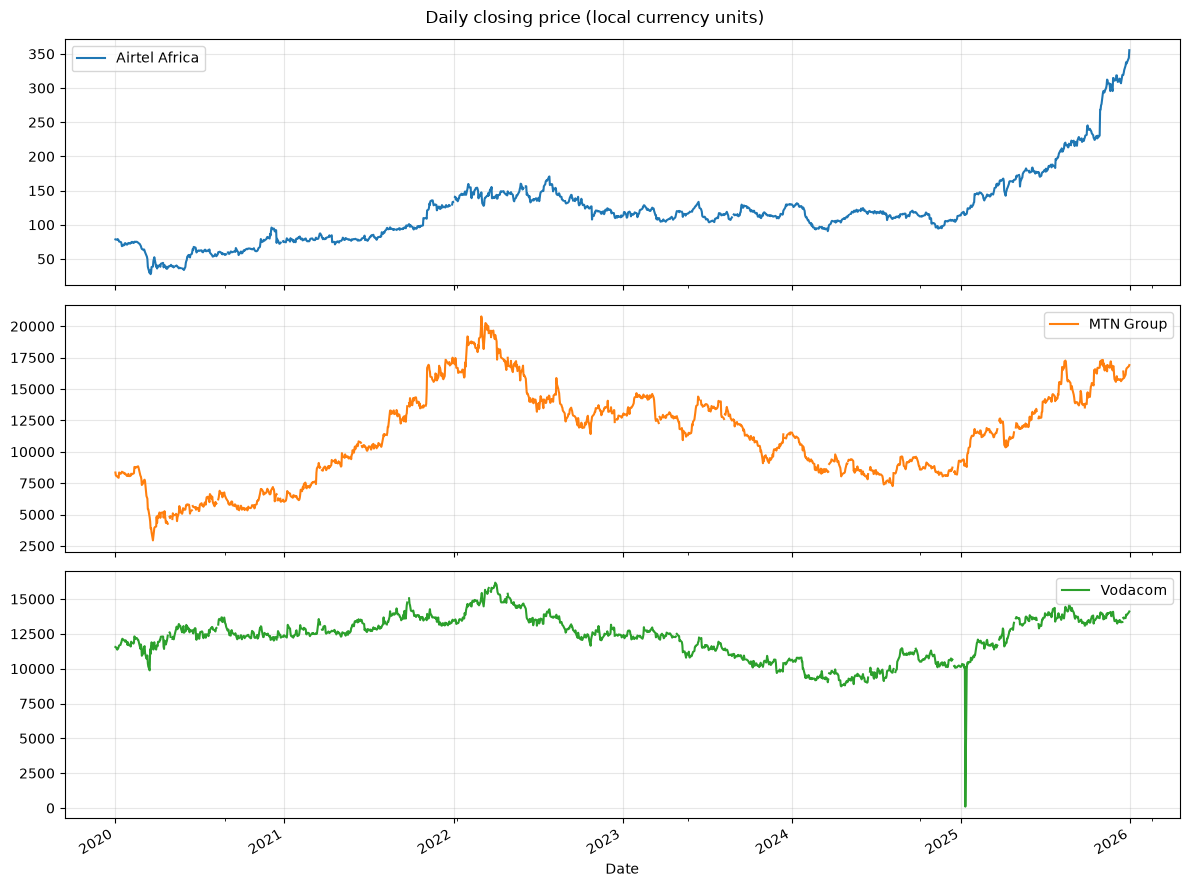

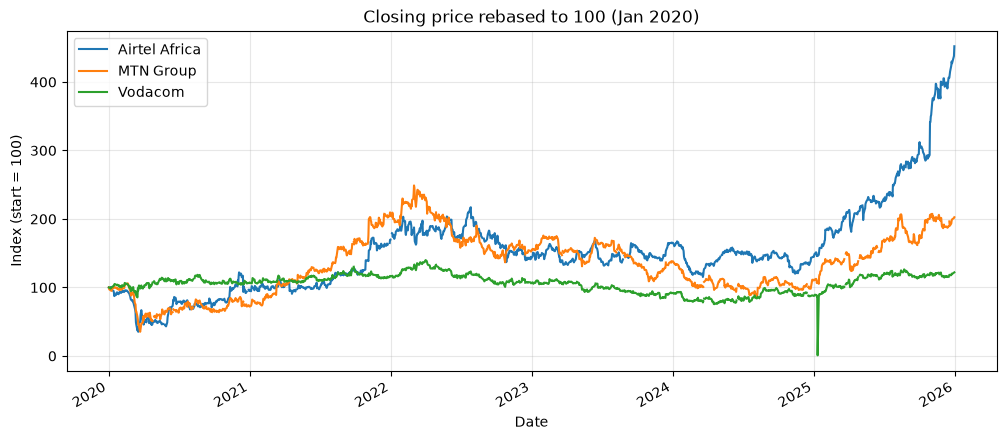

In [4]:
close = pd.DataFrame({name: df["Close"] for name, df in frames.items()})

close.plot(subplots=True, figsize=(12, 9), title="Daily closing price (local currency units)")
plt.tight_layout(); plt.show()

rebased = close / close.bfill().iloc[0] * 100
rebased.plot(title="Closing price rebased to 100 (Jan 2020)")
plt.ylabel("Index (start = 100)"); plt.show()

## 4. Resampling: weekly and monthly
`.resample()` turns daily data into longer-horizon trends. Closing price uses the last observation of each period.

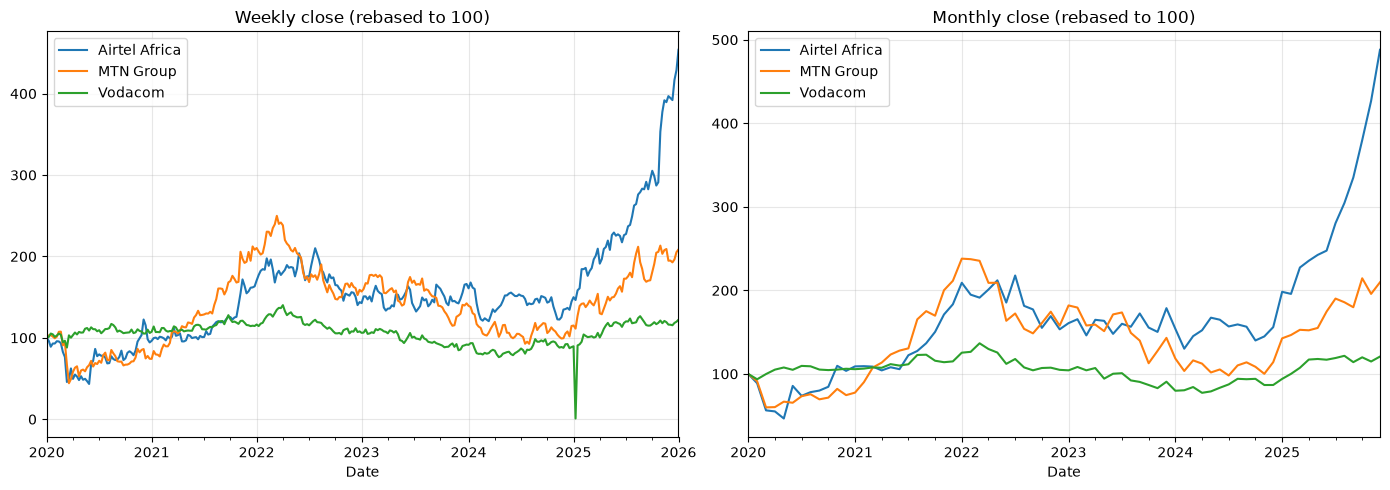

Average monthly return (%):
Airtel Africa    3.19
MTN Group        1.69
Vodacom          0.40
dtype: float64
Monthly volatility (std, %):
Airtel Africa    14.72
MTN Group        11.25
Vodacom           5.25
dtype: float64


In [5]:
weekly  = close.resample("W").last()
monthly = close.resample("ME").last()      

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)
(weekly / weekly.bfill().iloc[0] * 100).plot(ax=axes[0], title="Weekly close (rebased to 100)")
(monthly / monthly.bfill().iloc[0] * 100).plot(ax=axes[1], title="Monthly close (rebased to 100)")
plt.tight_layout(); plt.show()

monthly_returns = monthly.pct_change().dropna() * 100
print("Average monthly return (%):"); print(monthly_returns.mean().round(2))
print("Monthly volatility (std, %):"); print(monthly_returns.std().round(2))

## 5. Moving averages: 20-day and 200-day
The 20-day average shows short-term direction; the 200-day shows the long-term trend. When the 20-day crosses above the 200-day, traders call it a *golden cross*; below is a *death cross*.

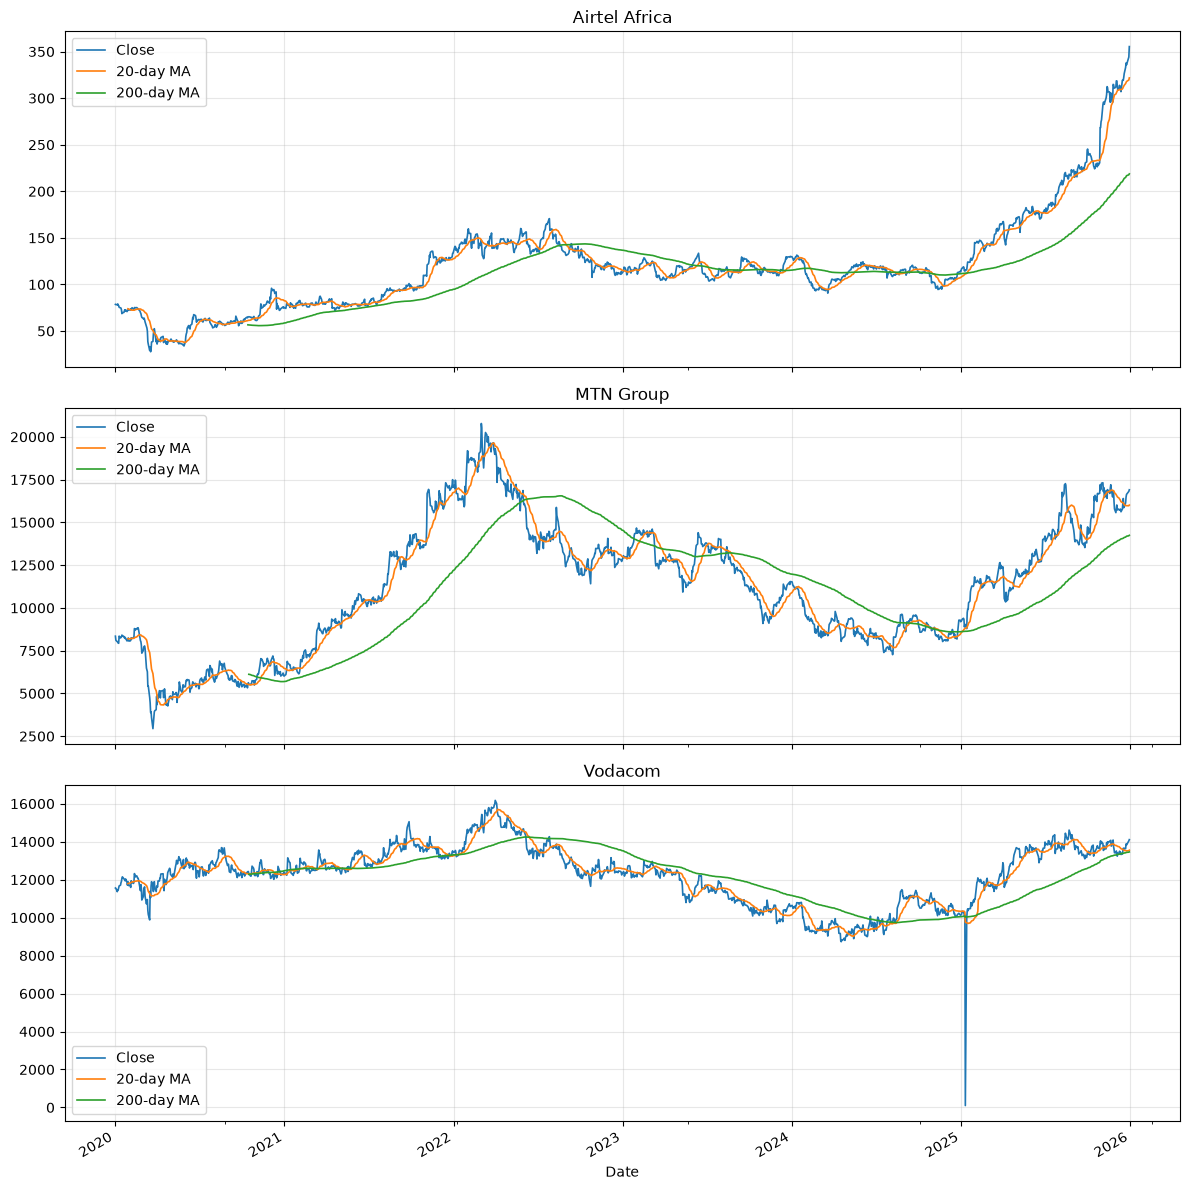

In [6]:
fig, axes = plt.subplots(len(frames), 1, figsize=(12, 4 * len(frames)), sharex=True)
for ax, (name, df) in zip(axes, frames.items()):
    ma = pd.DataFrame({
        "Close": df["Close"],
        "20-day MA": df["Close"].rolling(20).mean(),
        "200-day MA": df["Close"].rolling(200).mean(),
    })
    ma.plot(ax=ax, title=name, lw=1.2)
plt.tight_layout(); plt.show()

In [7]:
# Where does each stock end the period relative to its 200-day average?
for name, df in frames.items():
    last = df["Close"].iloc[-1]; ma200 = df["Close"].rolling(200).mean().iloc[-1]
    print(f"{name:14s} close vs 200-day MA: {(last/ma200 - 1)*100:+.1f}%")

Airtel Africa  close vs 200-day MA: +62.5%
MTN Group      close vs 200-day MA: +18.7%
Vodacom        close vs 200-day MA: +4.8%


## 6. Trading volume comparison

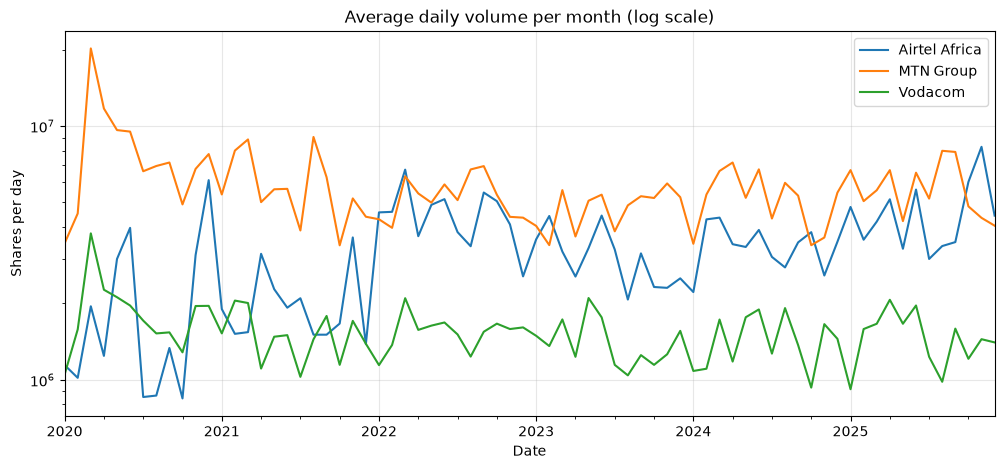

,Avg daily volume,Median daily volume,Peak day
Airtel Africa,3280655,2393012,82461685
MTN Group,5881375,4789886,82254233
Vodacom,1548444,1296895,11729490


In [8]:
volume = pd.DataFrame({name: df["Volume"] for name, df in frames.items()})

volume.resample("ME").mean().plot(logy=True, title="Average daily volume per month (log scale)")
plt.ylabel("Shares per day"); plt.show()

summary = pd.DataFrame({
    "Avg daily volume": volume.mean(),
    "Median daily volume": volume.median(),
    "Peak day": volume.max(),
}).round(0).astype(int)
summary

## 7. Local snapshot: TNM vs Airtel Malawi (MSE, Q3 2026)

yfinance has no feed for the Malawi Stock Exchange, so this section uses figures from the MSE *Quarterly Market Performance Report, Q3 2026* (July to September). It is a single-quarter summary, not a daily history, so no moving averages here.

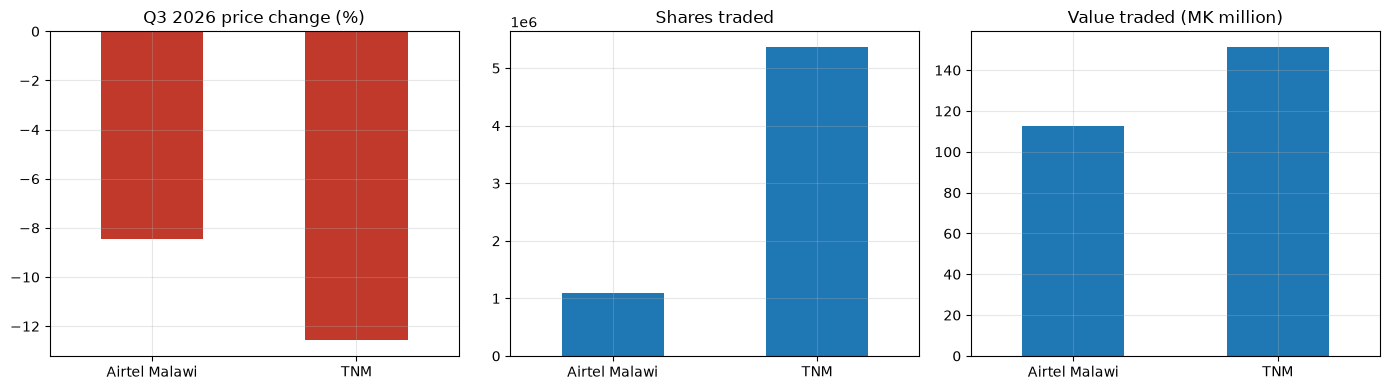

,Open (MK),Close (MK),Price change (%),Volume (shares),Value (MK),Trades,Avg price per share traded (MK)
Airtel Malawi,111.29,101.89,-8.45,1088106,1.126510e+08,409,103.53
TNM,29.17,25.50,-12.58,5370585,1.514504e+08,327,28.20


In [9]:
mse = pd.DataFrame({
    "Open (MK)":   [111.29, 29.17],
    "Close (MK)":  [101.89, 25.50],
    "Price change (%)": [-8.45, -12.58],
    "Volume (shares)":  [1_088_106, 5_370_585],
    "Value (MK)":       [112_650_993.34, 151_450_361.66],
    "Trades":           [409, 327],
}, index=["Airtel Malawi", "TNM"])
mse["Avg price per share traded (MK)"] = (mse["Value (MK)"] / mse["Volume (shares)"]).round(2)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
mse["Price change (%)"].plot.bar(ax=axes[0], color=["#c0392b"]*2, title="Q3 2026 price change (%)", rot=0)
mse["Volume (shares)"].plot.bar(ax=axes[1], title="Shares traded", rot=0)
mse["Value (MK)"].div(1e6).plot.bar(ax=axes[2], title="Value traded (MK million)", rot=0)
plt.tight_layout(); plt.show()
mse

## 8. Takeaways


- **Trend:** which of the three stocks ended 2025 highest on the rebased chart?
- **Momentum:** which sits above its 200-day average?
- **Liquidity:** how large is the volume gap between the three?
- **Malawi:** TNM and Airtel Malawi both fell in Q3 2026 (-12.58% and -8.45%), part of a market-wide decline where the MASI lost 6.44%. TNM traded more shares but at a far lower price per share, so Airtel Malawi still traded nearly as much by value.

**Limitations:** the main analysis uses parent or regional peers rather than the Malawi-listed shares; local figures come from a single quarterly report.

---
# Part 2: From analysis to a prediction pipeline

Part 1 describes what happened. Part 2 asks a harder question: **can anything known at today's close predict whether tomorrow's close will be higher?**

Rules for this section:
- Every feature for day *t* uses only data available at the close of day *t*.
- Train/test splits are **chronological** (walk-forward), never shuffled.
- Every model must beat a naive baseline to count as having learned anything.
- Backtests include trading costs and are compared with buy-and-hold.

## 9. Refresh and validate the data
Part 1 stops at 2025-12-30. This cell downloads through the latest available date, saves raw CSVs for reproducibility, and runs basic quality checks.

In [10]:
import numpy as np
from pathlib import Path
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

RAW = Path("../data/raw"); RAW.mkdir(parents=True, exist_ok=True)

full = {}
for ticker, name in TICKERS.items():
    df = yf.Ticker(ticker).history(start=START, auto_adjust=True)   # no END: up to the latest session
    df.index = df.index.tz_localize(None); df.index.name = "Date"
    df = df[["Open", "High", "Low", "Close", "Volume"]].dropna(subset=["Close"])
    df.to_csv(RAW / f"{ticker}.csv")
    full[name] = df

In [11]:
def quality_report(full):
    rows = []
    for name, df in full.items():
        r = df["Close"].pct_change()
        gaps = df.index.to_series().diff().dt.days
        rows.append({
            "stock": name,
            "rows": len(df),
            "first": df.index.min().date(),
            "last": df.index.max().date(),
            "zero-volume days": int((df["Volume"] == 0).sum()),
            "gaps > 5 days": int((gaps > 5).sum()),
            "|daily move| > 15%": int((r.abs() > 0.15).sum()),
            "duplicate dates": int(df.index.duplicated().sum()),
        })
    return pd.DataFrame(rows).set_index("stock")

quality_report(full)

,rows,first,last,zero-volume days,gaps > 5 days,|daily move| > 15%,duplicate dates
stock,,,,,,,
Airtel Africa,1725,2020-01-02,2026-10-29,0,0,10,0
MTN Group,1708,2020-01-02,2026-10-29,0,0,4,0
Vodacom,1708,2020-01-02,2026-10-29,0,0,3,0


## 10. Returns, volatility and co-movement
Daily returns are unitless, so they can be compared across pence and South African cents. Correlation uses only dates when both exchanges were open (London and Johannesburg have different holidays, which is why the row counts differ).

Share of up days:
Airtel Africa    0.514
MTN Group        0.490
Vodacom          0.485
dtype: float64

Daily return correlation (shared trading days only):
               Airtel Africa  MTN Group  Vodacom
Airtel Africa           1.00       0.31     0.01
MTN Group               0.31       1.00    -0.02
Vodacom                 0.01      -0.02     1.00


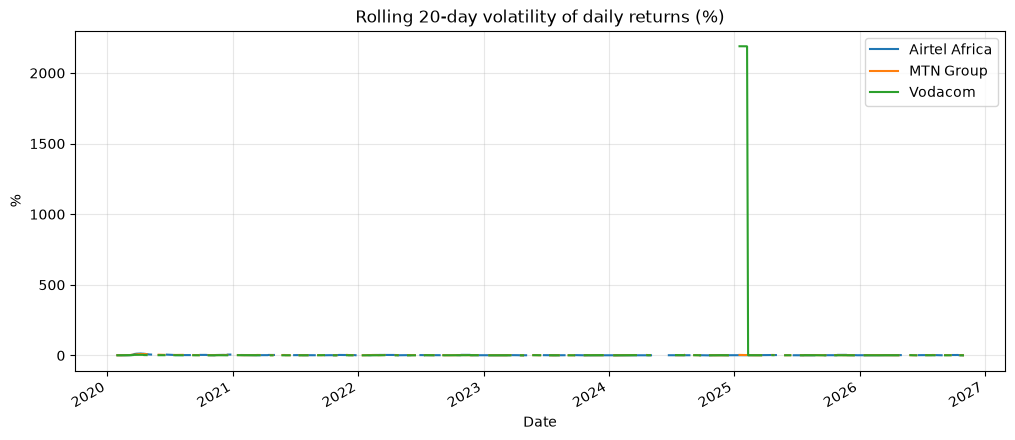

In [12]:
returns = pd.DataFrame({n: d["Close"].pct_change() for n, d in full.items()})

print("Share of up days:"); print((returns.dropna(how="all") > 0).mean().round(3))
print("\nDaily return correlation (shared trading days only):")
print(returns.dropna().corr().round(2))

returns.rolling(20).std().mul(100).plot(title="Rolling 20-day volatility of daily returns (%)")
plt.ylabel("%"); plt.show()

## 11. Feature engineering and target
**Target:** `1` if tomorrow's close is above today's close, else `0`.

**Features** (all computed from data up to and including day *t*): 1/5/20-day returns, 5/20-day rolling volatility, distance from the 20- and 200-day moving averages, volume relative to its 20-day average, high-low range and open-close return.

The last row of each stock is dropped because tomorrow is unknown.

In [13]:
FEATURES = ["ret_1", "ret_5", "ret_20", "vol_5", "vol_20",
            "dist_ma20", "dist_ma200", "rel_vol", "hl_range", "oc_ret"]

def make_features(df):
    c = df["Close"]; r = c.pct_change()
    f = pd.DataFrame(index=df.index)
    f["ret_1"], f["ret_5"], f["ret_20"] = r, c.pct_change(5), c.pct_change(20)
    f["vol_5"], f["vol_20"] = r.rolling(5).std(), r.rolling(20).std()
    f["dist_ma20"]  = c / c.rolling(20).mean() - 1
    f["dist_ma200"] = c / c.rolling(200).mean() - 1
    f["rel_vol"]    = df["Volume"] / df["Volume"].rolling(20).mean()
    f["hl_range"]   = (df["High"] - df["Low"]) / c
    f["oc_ret"]     = c / df["Open"] - 1
    f["next_ret"]   = r.shift(-1)                  # tomorrow's return: evaluation only, never a feature
    f["target"]     = (f["next_ret"] > 0).astype(int)
    return f.replace([np.inf, -np.inf], np.nan).dropna()   # drops warm-up rows and the final row

feats = {name: make_features(df) for name, df in full.items()}
for name, f in feats.items():
    print(f"{name:14s} usable rows: {len(f)}  | share of up days: {f['target'].mean():.3f}")

Airtel Africa  usable rows: 1525  | share of up days: 0.528
MTN Group      usable rows: 1508  | share of up days: 0.505
Vodacom        usable rows: 1508  | share of up days: 0.500


## 12. Walk-forward evaluation
The data is cut into 5 chronological folds. Each fold trains only on the past and predicts the next block (with a 1-day gap so the training labels never touch the test period). Every prediction in the results is therefore **out-of-sample**.

Models: a *majority-class baseline* (always predicts the more common direction), *Logistic Regression*, and a deliberately shallow *Random Forest*.

In [14]:
def make_models():
    return {
        "majority_baseline": DummyClassifier(strategy="most_frequent"),
        "logistic": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
        "random_forest": RandomForestClassifier(n_estimators=300, max_depth=4,
                                                min_samples_leaf=20, random_state=42, n_jobs=-1),
    }

def walk_forward(feat, n_splits=5):
    X, y = feat[FEATURES], feat["target"]
    proba = {m: pd.Series(np.nan, index=feat.index) for m in make_models()}
    for tr, te in TimeSeriesSplit(n_splits=n_splits, gap=1).split(X):
        for m_name, model in make_models().items():
            model.fit(X.iloc[tr], y.iloc[tr])
            proba[m_name].iloc[te] = model.predict_proba(X.iloc[te])[:, 1]
    return pd.DataFrame(proba).dropna()

preds, rows = {}, []
for name, feat in feats.items():
    preds[name] = walk_forward(feat)
    test = feat.loc[preds[name].index]
    for m in preds[name]:
        p = preds[name][m]
        rows.append({"stock": name, "model": m,
                     "accuracy": accuracy_score(test["target"], p > 0.5),
                     "roc_auc": 0.5 if m == "majority_baseline" else roc_auc_score(test["target"], p),
                     "test_up_share": test["target"].mean(), "test_days": len(test)})
results = pd.DataFrame(rows).set_index(["stock", "model"]).round(3)
results

accuracy  roc_auc  test_up_share  test_days
stock         model                                                         
Airtel Africa majority_baseline     0.528    0.500          0.528       1270
              logistic              0.518    0.502          0.528       1270
              random_forest         0.507    0.498          0.528       1270
MTN Group     majority_baseline     0.484    0.500          0.504       1255
              logistic              0.512    0.515          0.504       1255
              random_forest         0.508    0.511          0.504       1255
Vodacom       majority_baseline     0.495    0.500          0.505       1255
              logistic              0.520    0.527          0.505       1255
              random_forest         0.520    0.516          0.505       1255

## 13. Backtest against buy-and-hold
Strategy: hold the stock when the model's probability of an up day exceeds 0.5, otherwise stay in cash. A cost is charged each time the position changes. **Set `COST` to the real round-trip cost for each exchange**: UK stamp duty on purchases, brokerage and spreads can all be material, so 0.1% is only a placeholder.

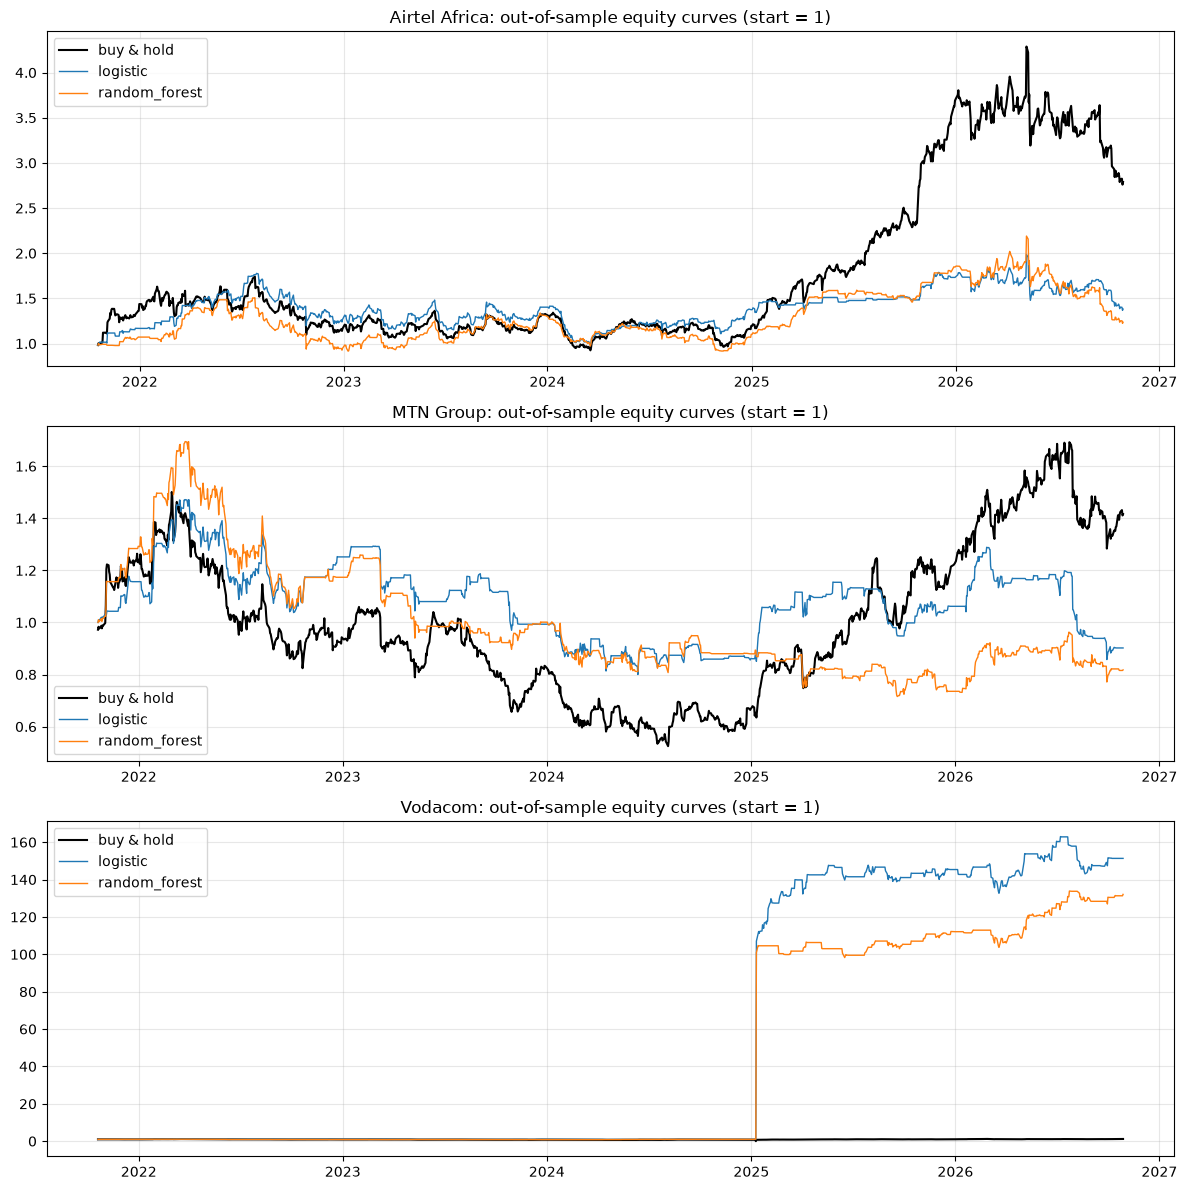

total_return  max_drawdown  trades  days_invested
stock         strategy                                                        
Airtel Africa buy_and_hold          1.788        -0.469       1          1.000
              logistic              0.382        -0.447     279          0.663
              random_forest         0.236        -0.441     337          0.683
MTN Group     buy_and_hold          0.416        -0.650       1          1.000
              logistic             -0.098        -0.456     272          0.438
              random_forest        -0.182        -0.578     379          0.467
Vodacom       buy_and_hold          0.178        -0.994       1          1.000
              logistic            150.339        -0.232     296          0.414
              random_forest       131.071        -0.217     315          0.357

In [15]:
COST = 0.001   # 0.1% per position change (placeholder, adjust)

def backtest(next_ret, p, cost=COST):
    pos = (p > 0.5).astype(int)
    trades = pos.diff().abs().fillna(pos.iloc[0])
    ret = pos * next_ret - trades * cost
    equity = (1 + ret).cumprod()
    return equity, {"total_return": equity.iloc[-1] - 1,
                    "max_drawdown": (equity / equity.cummax() - 1).min(),
                    "trades": int(trades.sum()),
                    "days_invested": float(pos.mean())}

bt_rows = []
fig, axes = plt.subplots(len(feats), 1, figsize=(12, 4 * len(feats)), sharex=False)
axes = np.atleast_1d(axes)
for ax, (name, feat) in zip(axes, feats.items()):
    nxt = feat.loc[preds[name].index, "next_ret"]
    bh = (1 + nxt).cumprod()
    ax.plot(bh, label="buy & hold", color="black", lw=1.5)
    bt_rows.append({"stock": name, "strategy": "buy_and_hold", "total_return": bh.iloc[-1] - 1,
                    "max_drawdown": (bh / bh.cummax() - 1).min(), "trades": 1, "days_invested": 1.0})
    for m in ["logistic", "random_forest"]:
        eq, stats = backtest(nxt, preds[name][m])
        ax.plot(eq, label=m, lw=1)
        bt_rows.append({"stock": name, "strategy": m, **stats})
    ax.set_title(f"{name}: out-of-sample equity curves (start = 1)"); ax.legend()
plt.tight_layout(); plt.show()

pd.DataFrame(bt_rows).set_index(["stock", "strategy"]).round(3)

## 14. Findings
*Fill this in after running the cells above. Suggested structure:*

- **Baseline:** what share of days were up, and what accuracy does "always predict up" get?
- **Models:** does either model beat that accuracy by a meaningful margin? Is ROC-AUC clearly above 0.5, or is it noise?
- **Backtest:** after costs, does the strategy beat buy-and-hold on return *and* drawdown? Remember that Airtel Africa ended Part 1 about 60% above its 200-day average, so a strategy that is simply long most of the time will look good in a strong uptrend without any real predictive skill.
- **Limitations:** about 1,300 usable days per stock, one market regime, no out-of-time holdout beyond the walk-forward folds, and costs are approximated.

**Possible next steps:** add the other stock's lagged return as a feature, try a return-regression target (MAE/RMSE), tune with nested walk-forward validation, and move the functions into `src/` modules.